In [12]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [13]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- Processing beta = 0.0625 ---
Loading cached filtered fields...

--- Processing beta = 1 ---
Loading cached filtered fields...

--- Processing beta = 16 ---
Loading cached filtered fields...


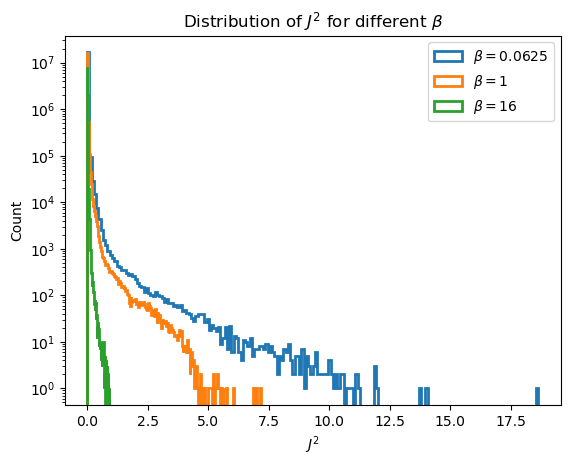

In [14]:
# -----------------------------
# USER SETTINGS
# -----------------------------
betas = [0.0625, 1, 16]

cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

# storage
J2_all = {}
mask_all = {}

# -----------------------------
# MAIN LOOP
# -----------------------------
for beta in betas:

    print(f"\n--- Processing beta = {beta} ---")

    # ----- FILE PATH -----
    base_path = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/'

    File_Bx = base_path + 'Bx_ApJ_t40.h5'
    File_By = base_path + 'By_ApJ_t40.h5'
    File_Bz = base_path + 'Bz_ApJ_t40.h5'

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    # ----- FILTER PARAMETERS -----
    if beta == 0.0625:
        n_iter, Xi = 1, 1.6
    elif beta == 1:
        n_iter, Xi = 2, 2.0
    else:
        n_iter, Xi = 3, 2.0

    cache_file = f"{cache_dir}/filtered_beta_{beta}_iter{n_iter}_Xi{Xi}.npz"

    # ----- LOAD OR COMPUTE FILTERED FIELDS -----
    if os.path.exists(cache_file):
        print("Loading cached filtered fields...")
        data = np.load(cache_file)
        data_Bx_f = data['Bx']
        data_By_f = data['By']
        data_Bz_f = data['Bz']

    else:
        print("Computing filtering (slow)...")

        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi
        )

        np.savez_compressed(
            cache_file,
            Bx=data_Bx_f,
            By=data_By_f,
            Bz=data_Bz_f
        )

    # ----- CURRENT DENSITY -----
    Jx = partial_y_fft(data_Bz_f, dx)
    Jy = -partial_x_fft(data_Bz_f, dy)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)

    J2 = Jx**2 + Jy**2 + Jz**2
    
    # J2_norm = J2 / np.mean(J2)
    # J2 = J2_norm

    plt.hist(J2.ravel(), bins=200, log=True,
         histtype='step', linewidth=2,
         label=fr'$\beta = {beta}$')
    
    # ----- CURRENT SHEET DETECTION -----
    sheets = detect_current_sheets(J2)

    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1

    # ----- MORPHOLOGICAL CLEANING -----
    struct = morphology.disk(5)

    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500
    ).astype(int)

    # store
    J2_all[beta] = J2
    mask_all[beta] = mask

plt.legend()
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title(r'Distribution of $J^2$ for different $\beta$')
plt.savefig(RESULTS / 'J2_full.png')
plt.show()

# -----------------------------
# GLOBAL COLOR SCALE
# -----------------------------
all_values = np.concatenate([J2_all[b].ravel() for b in betas])
vmax_global = np.percentile(all_values, 99)

beta=0.0625: 707572 CS pixels (4.22% of domain), mean J2 in CS = 9.936e-02, full-field mean = 9.003e-03
beta=1: 573878 CS pixels (3.42% of domain), mean J2 in CS = 1.122e-01, full-field mean = 1.197e-02
beta=16: 731441 CS pixels (4.36% of domain), mean J2 in CS = 3.598e-02, full-field mean = 7.409e-03


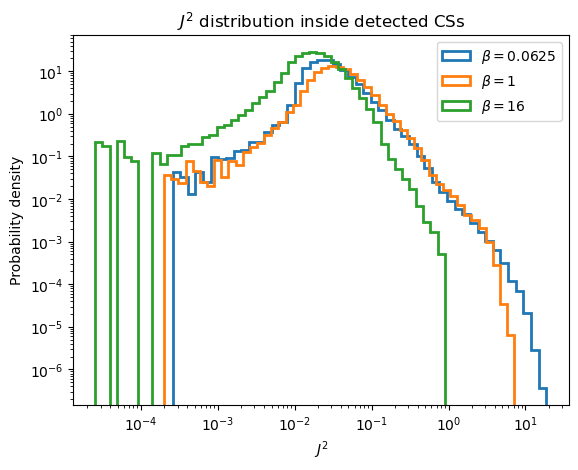

In [15]:
plt.figure()
for beta in betas:
    J2   = J2_all[beta]
    mask = mask_all[beta].astype(bool)        # <-- THIS is the critical line
    J2_cs = J2[mask]                          # now correct: 1D array of CS-only values
    J2_cs = J2_cs[J2_cs > 0]

    print(f"beta={beta}: {mask.sum()} CS pixels "
          f"({100*mask.mean():.2f}% of domain), "
          f"mean J2 in CS = {J2_cs.mean():.3e}, full-field mean = {J2.mean():.3e}")

    bins = np.logspace(np.log10(J2_cs.min()), np.log10(J2_cs.max()), 50)
    plt.hist(J2_cs, bins=bins, density=True,
             histtype='step', linewidth=2,
             label=fr'$\beta = {beta}$')

plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'$J^2$'); plt.ylabel('Probability density')
plt.title(r'$J^2$ distribution inside detected CSs')
plt.savefig(RESULTS / 'J2_inside.png')
plt.legend()
plt.show()

beta = 0.0625
  inside  CSs: N=  707572  (4.22% of domain), mean J2 = 9.936e-02, median = 4.340e-02
  outside CSs: N=16069644  (95.78% of domain), mean J2 = 5.025e-03, median = 2.379e-03


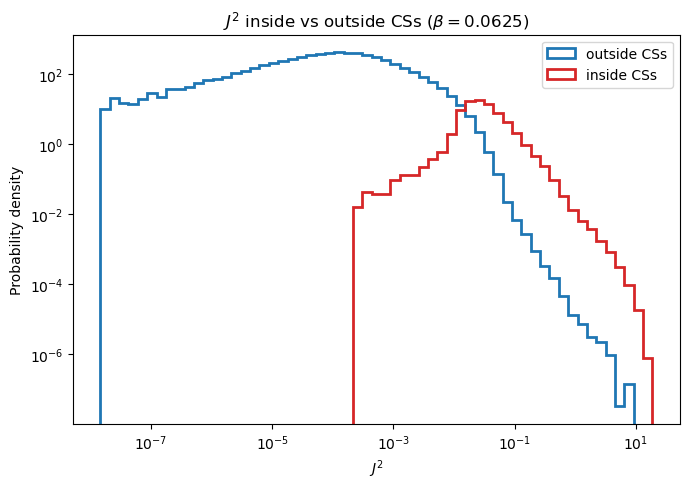

In [16]:
beta = 0.0625                                    # pick the run
J2   = J2_all[beta]
mask = mask_all[beta].astype(bool)          # boolean — critical, as before

J2_in  = J2[mask]                           # inside CSs
J2_out = J2[~mask]                          # outside CSs
J2_in  = J2_in[J2_in > 0]
J2_out = J2_out[J2_out > 0]

print(f"beta = {beta}")
print(f"  inside  CSs: N={J2_in.size:>8d}  ({100*mask.mean():.2f}% of domain), "
      f"mean J2 = {J2_in.mean():.3e}, median = {np.median(J2_in):.3e}")
print(f"  outside CSs: N={J2_out.size:>8d}  ({100*(~mask).mean():.2f}% of domain), "
      f"mean J2 = {J2_out.mean():.3e}, median = {np.median(J2_out):.3e}")

# shared log-spaced bins so the two histograms are directly comparable
lo = min(J2_in.min(), J2_out.min())
hi = max(J2_in.max(), J2_out.max())
bins = np.logspace(np.log10(lo), np.log10(hi), 60)

plt.figure(figsize=(7, 5))
plt.hist(J2_out, bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:blue', label='outside CSs')
plt.hist(J2_in,  bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:red',  label='inside CSs')
plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'$J^2$'); plt.ylabel('Probability density')
plt.title(fr'$J^2$ inside vs outside CSs ($\beta = {beta}$)')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / 'J2_insideVsoutside_beta0.0625.png')
plt.show()

beta = 1
  inside  CSs: N=  573878  (3.42% of domain), mean J2 = 1.122e-01, median = 5.808e-02
  outside CSs: N=16203338  (96.58% of domain), mean J2 = 8.425e-03, median = 5.303e-03


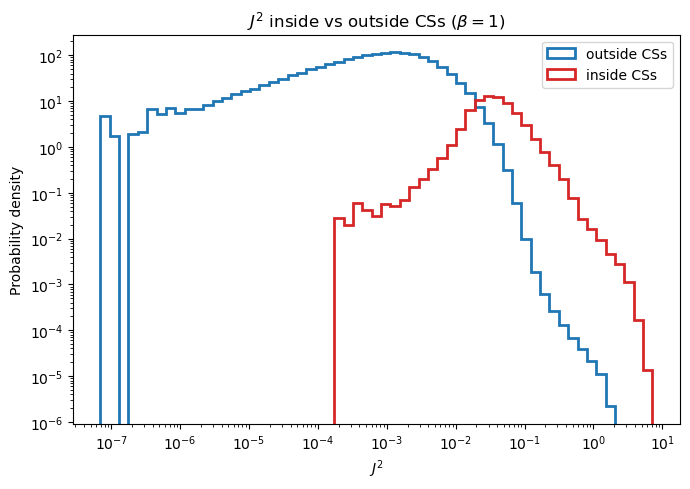

In [17]:
beta = 1                                    # pick the run
J2   = J2_all[beta]
mask = mask_all[beta].astype(bool)          # boolean — critical, as before

J2_in  = J2[mask]                           # inside CSs
J2_out = J2[~mask]                          # outside CSs
J2_in  = J2_in[J2_in > 0]
J2_out = J2_out[J2_out > 0]

print(f"beta = {beta}")
print(f"  inside  CSs: N={J2_in.size:>8d}  ({100*mask.mean():.2f}% of domain), "
      f"mean J2 = {J2_in.mean():.3e}, median = {np.median(J2_in):.3e}")
print(f"  outside CSs: N={J2_out.size:>8d}  ({100*(~mask).mean():.2f}% of domain), "
      f"mean J2 = {J2_out.mean():.3e}, median = {np.median(J2_out):.3e}")

# shared log-spaced bins so the two histograms are directly comparable
lo = min(J2_in.min(), J2_out.min())
hi = max(J2_in.max(), J2_out.max())
bins = np.logspace(np.log10(lo), np.log10(hi), 60)

plt.figure(figsize=(7, 5))
plt.hist(J2_out, bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:blue', label='outside CSs')
plt.hist(J2_in,  bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:red',  label='inside CSs')
plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'$J^2$'); plt.ylabel('Probability density')
plt.title(fr'$J^2$ inside vs outside CSs ($\beta = {beta}$)')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / 'J2_insideVsoutside_beta1.png')
plt.show()

beta = 16
  inside  CSs: N=  731441  (4.36% of domain), mean J2 = 3.598e-02, median = 2.663e-02
  outside CSs: N=16045775  (95.64% of domain), mean J2 = 6.107e-03, median = 4.351e-03


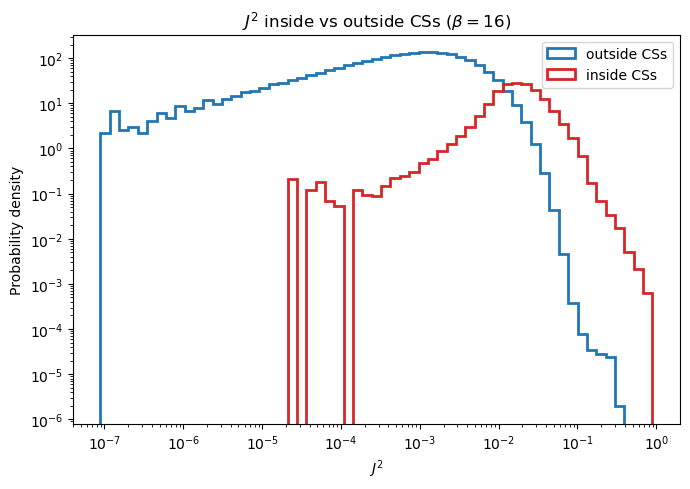

In [18]:
beta = 16                                    # pick the run
J2   = J2_all[beta]
mask = mask_all[beta].astype(bool)          # boolean — critical, as before

J2_in  = J2[mask]                           # inside CSs
J2_out = J2[~mask]                          # outside CSs
J2_in  = J2_in[J2_in > 0]
J2_out = J2_out[J2_out > 0]

print(f"beta = {beta}")
print(f"  inside  CSs: N={J2_in.size:>8d}  ({100*mask.mean():.2f}% of domain), "
      f"mean J2 = {J2_in.mean():.3e}, median = {np.median(J2_in):.3e}")
print(f"  outside CSs: N={J2_out.size:>8d}  ({100*(~mask).mean():.2f}% of domain), "
      f"mean J2 = {J2_out.mean():.3e}, median = {np.median(J2_out):.3e}")

# shared log-spaced bins so the two histograms are directly comparable
lo = min(J2_in.min(), J2_out.min())
hi = max(J2_in.max(), J2_out.max())
bins = np.logspace(np.log10(lo), np.log10(hi), 60)

plt.figure(figsize=(7, 5))
plt.hist(J2_out, bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:blue', label='outside CSs')
plt.hist(J2_in,  bins=bins, density=True, histtype='step',
         linewidth=2, color='tab:red',  label='inside CSs')
plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'$J^2$'); plt.ylabel('Probability density')
plt.title(fr'$J^2$ inside vs outside CSs ($\beta = {beta}$)')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / 'J2_insideVsoutside_beta16.png')
plt.show()